1. Data Loading and Initial Inspection

In this section, we load the Superstore dataset using Pandas and preview the first five rows to understand the structure of the data.

In [1]:
import pandas as pd

df = pd.read_csv("Sample - Superstore.csv", encoding="latin1")

df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


2. Data Quality Checks

In this section, we inspect the dataset's structure, data types, missing values, and duplicate rows to assess data quality before performing the analysis.

In [2]:
print("Dataset Shape:", df.shape)

print("\nNumber of Rows:", df.shape[0])

print("Number of Columns:", df.shape[1])

Dataset Shape: (9994, 21)

Number of Rows: 9994
Number of Columns: 21


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       9994

In [4]:
df.isnull().sum()

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

In [5]:
print("Number of Duplicate Rows:", df.duplicated().sum())

Number of Duplicate Rows: 0


3. Date Feature Engineering

In this section, we convert order dates into datetime format and extract useful time-based features, such as year and month, to support trend analysis.

In [6]:
df["Order Date"] = pd.to_datetime(df["Order Date"])

df["Ship Date"] = pd.to_datetime(df["Ship Date"])

df[["Order Date", "Ship Date"]].dtypes

Order Date    datetime64[us]
Ship Date     datetime64[us]
dtype: object

4. Exploratory Data Analysis (EDA)

In this section, we explore the numerical features of the dataset using descriptive statistics to understand sales, quantity, discounts, and profit distributions.

In [7]:
df[["Sales", "Quantity", "Discount", "Profit"]].describe()

,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000
mean,229.858001,3.789574,0.156203,28.656896
std,623.245101,2.225110,0.206452,234.260108
min,0.444000,1.000000,0.000000,-6599.978000
25%,17.280000,2.000000,0.000000,1.728750
50%,54.490000,3.000000,0.200000,8.666500
75%,209.940000,5.000000,0.200000,29.364000
max,22638.480000,14.000000,0.800000,8399.976000


In [8]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_quantity = df["Quantity"].sum()

print(f"Total Sales: ${total_sales:,.2f}")
print(f"Total Profit: ${total_profit:,.2f}")
print(f"Total Quantity Sold: {total_quantity:,}")

Total Sales: $2,297,200.86
Total Profit: $286,397.02
Total Quantity Sold: 37,873


5. Sales and Profitability Analysis

This section analyzes sales, profit, and profit margins across different business dimensions to identify strong performers and areas that may need improvement.

In [9]:
category_analysis = df.groupby("Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum")
).round(2)

category_analysis

,Total_Sales,Total_Profit,Total_Quantity
Category,,,
Furniture,741999.80,18451.27,8028
Office Supplies,719047.03,122490.80,22906
Technology,836154.03,145454.95,6939


5.1 Category Analysis

This analysis compares sales, total profit, and profit margins across product categories to identify which categories perform best.

In [10]:
category_analysis["Profit_Margin_%"] = (
    category_analysis["Total_Profit"]
    / category_analysis["Total_Sales"]
    * 100
).round(2)

category_analysis

,Total_Sales,Total_Profit,Total_Quantity,Profit_Margin_%
Category,,,,
Furniture,741999.80,18451.27,8028,2.49
Office Supplies,719047.03,122490.80,22906,17.04
Technology,836154.03,145454.95,6939,17.40


5.2 Region Analysis

This analysis compares sales, total profit, and profit margins across regions to identify strong-performing regions and areas that may need improvement.

In [11]:
region_analysis = df.groupby("Region").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum")
).round(2)

region_analysis.sort_values(
    by="Total_Sales",
    ascending=False
)

,Total_Sales,Total_Profit,Total_Quantity
Region,,,
West,725457.82,108418.45,12266
East,678781.24,91522.78,10618
Central,501239.89,39706.36,8780
South,391721.90,46749.43,6209


5.3 Yearly Sales Analysis

This analysis examines yearly sales and profit trends from 2014 to 2017 to understand business growth and changes in financial performance over time.

In [12]:
df["Order Year"] = df["Order Date"].dt.year

yearly_analysis = df.groupby("Order Year").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum")
).round(2)

yearly_analysis

,Total_Sales,Total_Profit,Total_Quantity
Order Year,,,
2014,484247.50,49543.97,7581
2015,470532.51,61618.60,7979
2016,609205.60,81795.17,9837
2017,733215.26,93439.27,12476


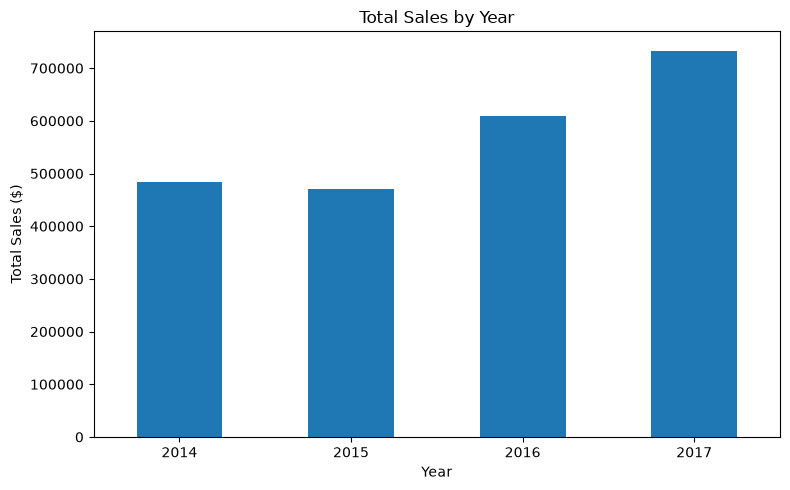

In [13]:
import matplotlib.pyplot as plt

yearly_analysis["Total_Sales"].plot(
    kind="bar",
    figsize=(8, 5),
    title="Total Sales by Year"
)

plt.xlabel("Year")
plt.ylabel("Total Sales ($)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

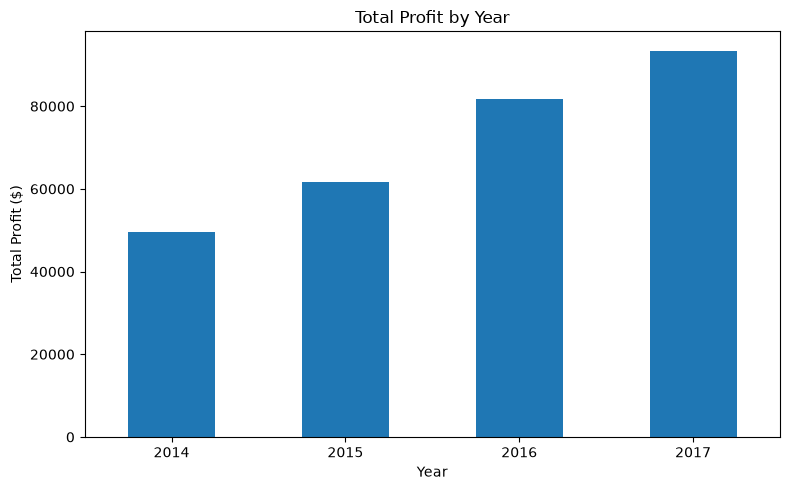

In [14]:
yearly_analysis["Total_Profit"].plot(
    kind="bar",
    figsize=(8, 5),
    title="Total Profit by Year"
)

plt.xlabel("Year")
plt.ylabel("Total Profit ($)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

5.4 Product Profitability Analysis

This analysis evaluates product-level sales and profitability to identify the most profitable products and those generating losses.

In [15]:
product_profit = df.groupby("Product Name").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum")
)

top_10_products = product_profit.sort_values(
    by="Total_Profit",
    ascending=False
).head(10)

top_10_products.round(2)

,Total_Sales,Total_Profit,Total_Quantity
Product Name,,,
Canon imageCLASS 2200 Advanced Copier,61599.82,25199.93,20
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,27453.38,7753.04,31
Hewlett Packard LaserJet 3310 Copier,18839.69,6983.88,38
Canon PC1060 Personal Laser Copier,11619.83,4570.93,19
"HP Designjet T520 Inkjet Large Format Printer - 24"" Color",18374.90,4094.98,12
Ativa V4110MDD Micro-Cut Shredder,7699.89,3772.95,11
"3D Systems Cube Printer, 2nd Generation, Magenta",14299.89,3717.97,11
Plantronics Savi W720 Multi-Device Wireless Headset System,9367.29,3696.28,24
Ibico EPK-21 Electric Binding System,15875.92,3345.28,13


In [16]:
bottom_10_products = product_profit.sort_values(
    by="Total_Profit",
    ascending=True
).head(10)

bottom_10_products.round(2)

,Total_Sales,Total_Profit,Total_Quantity
Product Name,,,
Cubify CubeX 3D Printer Double Head Print,11099.96,-8879.97,9
Lexmark MX611dhe Monochrome Laser Printer,16829.90,-4589.97,18
Cubify CubeX 3D Printer Triple Head Print,7999.98,-3839.99,4
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases,9917.64,-2876.12,27
Bush Advantage Collection Racetrack Conference Table,9544.72,-1934.40,33
GBC DocuBind P400 Electric Binding System,17965.07,-1878.17,27
Cisco TelePresence System EX90 Videoconferencing Unit,22638.48,-1811.08,6
Martin Yale Chadless Opener Electric Letter Opener,16656.20,-1299.18,22
Balt Solid Wood Round Tables,6518.75,-1201.06,19


In [17]:
discount_analysis = df.groupby("Discount").agg(
    Number_of_Orders=("Order ID", "count"),
    Average_Sales=("Sales", "mean"),
    Average_Profit=("Profit", "mean"),
    Total_Profit=("Profit", "sum")
).round(2)

discount_analysis

,Number_of_Orders,Average_Sales,Average_Profit,Total_Profit
Discount,,,,
0.00,4798,226.74,66.90,320987.60
0.10,94,578.40,96.06,9029.18
0.15,52,529.97,27.29,1418.99
0.20,3657,209.08,24.70,90337.31
0.30,227,454.74,-45.68,-10369.28
0.32,27,536.79,-88.56,-2391.14
0.40,206,565.13,-111.93,-23057.05
0.45,11,498.63,-226.65,-2493.11
0.50,66,892.71,-310.70,-20506.43


5.5 Discount Analysis

This analysis examines how different discount levels are associated with average sales and profit to identify discount groups that may be linked to lower profitability.

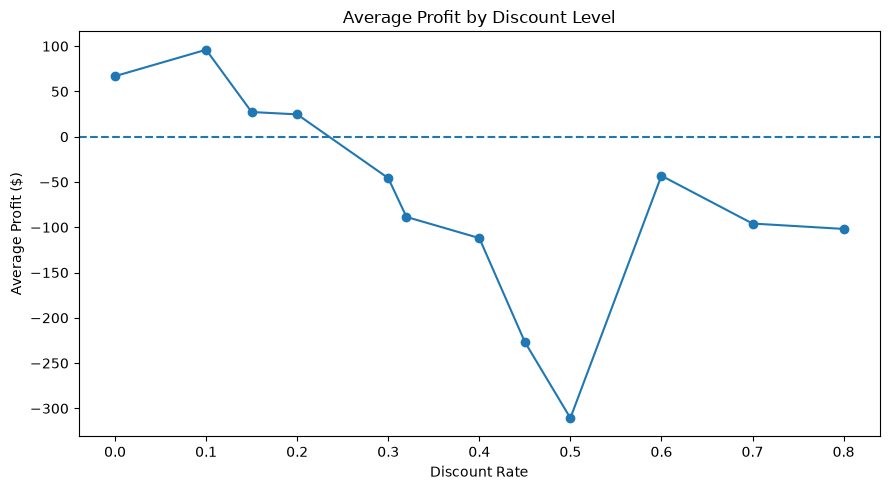

In [18]:
discount_analysis["Average_Profit"].plot(
    kind="line",
    marker="o",
    figsize=(9, 5),
    title="Average Profit by Discount Level"
)

plt.axhline(y=0, linestyle="--")
plt.xlabel("Discount Rate")
plt.ylabel("Average Profit ($)")
plt.tight_layout()
plt.show()

5.6 Sub-Category Analysis

This analysis compares sales, total profit, and profit margins across product sub-categories to identify the most and least profitable product groups.

In [19]:
subcategory_analysis = df.groupby("Sub-Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum")
)

subcategory_analysis = subcategory_analysis.sort_values(
    by="Total_Profit",
    ascending=False
)

subcategory_analysis.round(2)

,Total_Sales,Total_Profit,Total_Quantity
Sub-Category,,,
Copiers,149528.03,55617.82,234
Phones,330007.05,44515.73,3289
Accessories,167380.32,41936.64,2976
Paper,78479.21,34053.57,5178
Binders,203412.73,30221.76,5974
Chairs,328449.10,26590.17,2356
Storage,223843.61,21278.83,3158
Appliances,107532.16,18138.01,1729
Furnishings,91705.16,13059.14,3563


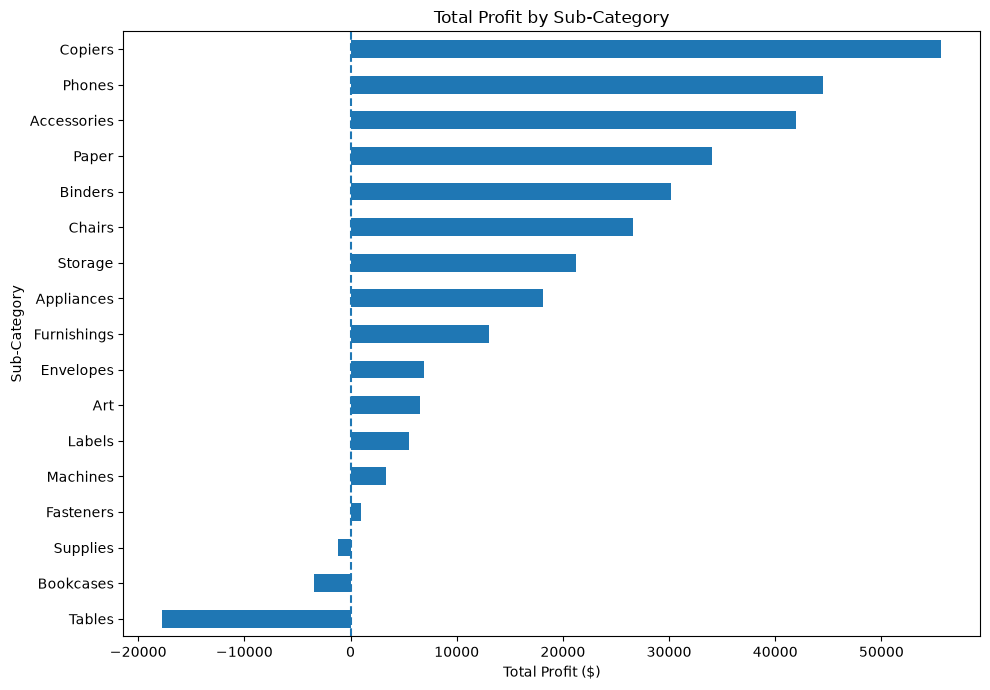

In [20]:
subcategory_analysis["Total_Profit"].sort_values().plot(
    kind="barh",
    figsize=(10, 7),
    title="Total Profit by Sub-Category"
)

plt.axvline(x=0, linestyle="--")
plt.xlabel("Total Profit ($)")
plt.ylabel("Sub-Category")
plt.tight_layout()
plt.show()

5.7 Monthly Sales Analysis

This analysis examines monthly sales and profit trends across different years to identify peak-performing periods and potential seasonal patterns.

In [21]:
df["Order Month"] = df["Order Date"].dt.month

monthly_sales = df.groupby(
    ["Order Year", "Order Month"]
).agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum")
).round(2)

monthly_sales.head(15)

Total_Sales  Total_Profit
Order Year Order Month                           
2014       1               14236.90       2450.19
           2                4519.89        862.31
           3               55691.01        498.73
           4               28295.34       3488.84
           5               23648.29       2738.71
           6               34595.13       4976.52
           7               33946.39       -841.48
           8               27909.47       5318.10
           9               81777.35       8328.10
           10              31453.39       3448.26
           11              78628.72       9292.13
           12              69545.62       8983.57
2015       1               18174.08      -3281.01
           2               11951.41       2813.85
           3               38726.25       9732.10

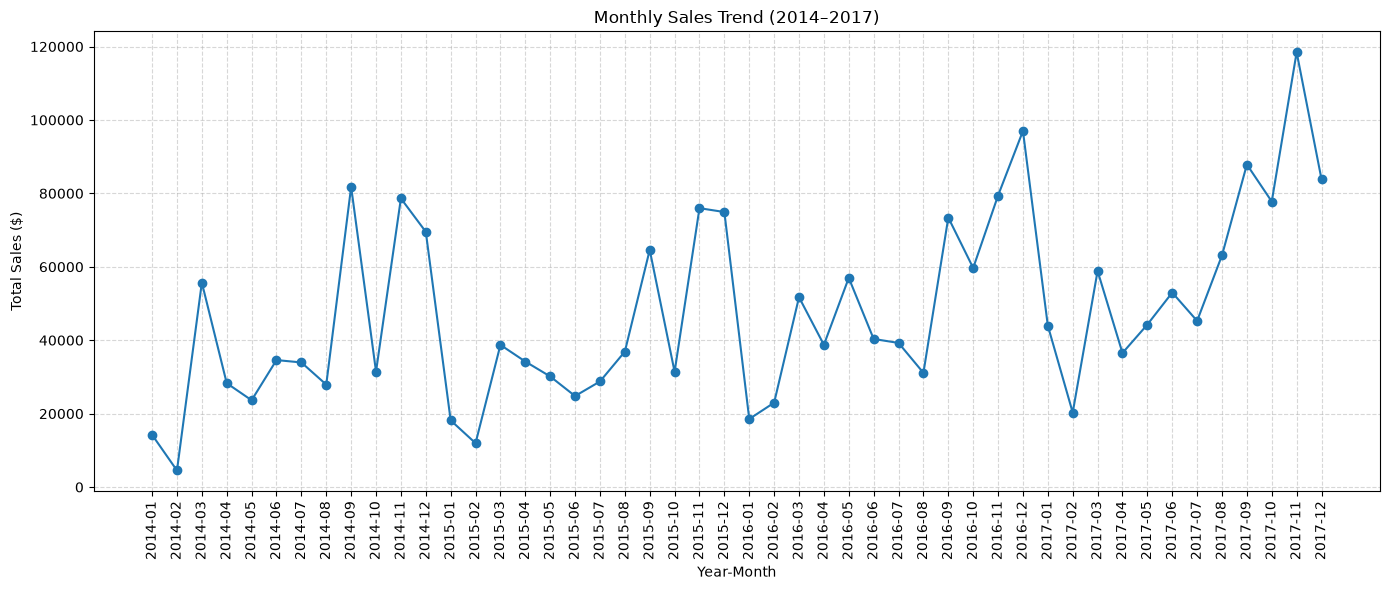

In [22]:
monthly_sales = monthly_sales.reset_index()

monthly_sales["Year_Month"] = (
    monthly_sales["Order Year"].astype(str)
    + "-"
    + monthly_sales["Order Month"].astype(str).str.zfill(2)
)

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales["Year_Month"],
    monthly_sales["Total_Sales"],
    marker="o"
)

plt.title("Monthly Sales Trend (2014–2017)")
plt.xlabel("Year-Month")
plt.ylabel("Total Sales ($)")
plt.xticks(rotation=90)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [23]:
best_sales_month = monthly_sales.loc[
    monthly_sales["Total_Sales"].idxmax()
]

worst_sales_month = monthly_sales.loc[
    monthly_sales["Total_Sales"].idxmin()
]

best_profit_month = monthly_sales.loc[
    monthly_sales["Total_Profit"].idxmax()
]

worst_profit_month = monthly_sales.loc[
    monthly_sales["Total_Profit"].idxmin()
]

print("Highest Sales Month:")
print(best_sales_month[["Year_Month", "Total_Sales"]])

print("\nLowest Sales Month:")
print(worst_sales_month[["Year_Month", "Total_Sales"]])

print("\nHighest Profit Month:")
print(best_profit_month[["Year_Month", "Total_Profit"]])

print("\nLowest Profit Month:")
print(worst_profit_month[["Year_Month", "Total_Profit"]])

Highest Sales Month:
Year_Month       2017-11
Total_Sales    118447.82
Name: 46, dtype: object

Lowest Sales Month:
Year_Month     2014-02
Total_Sales    4519.89
Name: 1, dtype: object

Highest Profit Month:
Year_Month       2016-12
Total_Profit    17885.31
Name: 35, dtype: object

Lowest Profit Month:
Year_Month      2015-01
Total_Profit   -3281.01
Name: 12, dtype: object


5.8 Customer Segment Analysis

This analysis compares sales, profit, and profit margins across customer segments to understand which groups contribute most to business performance.

In [24]:
segment_analysis = df.groupby("Segment").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum")
).round(2)

segment_analysis["Profit_Margin_%"] = (
    segment_analysis["Total_Profit"]
    / segment_analysis["Total_Sales"] * 100
).round(2)

segment_analysis.sort_values(
    by="Total_Sales",
    ascending=False
)

,Total_Sales,Total_Profit,Total_Quantity,Profit_Margin_%
Segment,,,,
Consumer,1161401.34,134119.21,19521,11.55
Corporate,706146.37,91979.13,11608,13.03
Home Office,429653.15,60298.68,6744,14.03


5.9 Shipping Analysis

This analysis compares sales, profit, and profit margins across shipping modes to understand their contribution to overall business performance.

In [25]:
shipping_analysis = df.groupby("Ship Mode").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique")
).round(2)

shipping_analysis["Profit_Margin_%"] = (
    shipping_analysis["Total_Profit"]
    / shipping_analysis["Total_Sales"] * 100
).round(2)

shipping_analysis.sort_values(
    by="Total_Sales",
    ascending=False
)

,Total_Sales,Total_Profit,Total_Orders,Profit_Margin_%
Ship Mode,,,,
Standard Class,1358215.74,164088.79,2994,12.08
Second Class,459193.57,57446.64,964,12.51
First Class,351428.42,48969.84,787,13.93
Same Day,128363.12,15891.76,264,12.38


6. Key Performance Indicators (KPIs)

This section calculates key business metrics, including total sales, total profit, profit margin, total orders, unique customers, quantity sold, and average order value.

In [26]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_orders = df["Order ID"].nunique()
total_customers = df["Customer ID"].nunique()
total_quantity = df["Quantity"].sum()

profit_margin = (total_profit / total_sales) * 100
average_order_value = total_sales / total_orders

print(f"Total Sales: ${total_sales:,.2f}")
print(f"Total Profit: ${total_profit:,.2f}")
print(f"Profit Margin: {profit_margin:.2f}%")
print(f"Total Orders: {total_orders:,}")
print(f"Total Customers: {total_customers:,}")
print(f"Total Quantity Sold: {total_quantity:,}")
print(f"Average Order Value: ${average_order_value:,.2f}")

Total Sales: $2,297,200.86
Total Profit: $286,397.02
Profit Margin: 12.47%
Total Orders: 5,009
Total Customers: 793
Total Quantity Sold: 37,873
Average Order Value: $458.61


7. Exporting Analysis Results

In this section, we export the analysis results to CSV files for further analysis, reporting, and reuse in other tools.

In [29]:
category_analysis.to_csv("category_analysis.csv")
region_analysis.to_csv("region_analysis.csv")
yearly_analysis.to_csv("yearly_analysis.csv")
top_10_products.to_csv("top_10_products.csv")
bottom_10_products.to_csv("bottom_10_products.csv")
discount_analysis.to_csv("discount_analysis.csv")
subcategory_analysis.to_csv("subcategory_analysis.csv")
segment_analysis.to_csv("segment_analysis.csv")
shipping_analysis.to_csv("shipping_analysis.csv")
monthly_sales.to_csv("monthly_sales.csv")

print("All analysis files exported successfully!")

All analysis files exported successfully!


Sales Data Analysis – Superstore Dataset

Project Overview

This project explores retail sales data to identify business trends, evaluate profitability, and discover opportunities for improvement.

Dataset

- Records: 9,994
- Original Features: 21 columns
- Analysis Period: 2014–2017
- Data Quality: No missing values or duplicate rows were found during the initial checks.

Tools & Technologies

- Python
- Pandas
- Matplotlib
- Jupyter Notebook

Key Performance Indicators

- Total Sales: $2,297,200.86
- Total Profit: $286,397.02
- Profit Margin: 12.47%
- Total Orders: 5,009
- Unique Customers: 793
- Average Order Value: $458.61

Key Findings

- Technology generated the highest sales and total profit among the three main product categories.
- The Central region had the lowest profit margin at 7.92%.
- Tables recorded the largest total loss among sub-categories, at $17,725.48.
- Home Office customers had the highest profit margin among customer segments, at 14.03%.
- November 2017 recorded the highest monthly sales, while December 2016 recorded the highest monthly profit.
- Higher discount levels were associated with negative average profit for several discount groups.

Business Recommendations

- Investigate pricing, discounts, and product costs in low-profit categories and regions.
- Review loss-making products to identify opportunities to improve profitability.
- Evaluate discount policies using both sales and profit metrics.
- Explore growth opportunities among profitable customer segments.
- Monitor monthly performance to support sales planning.

Project Workflow

1. Data loading and inspection
2. Data quality checks
3. Date feature extraction
4. Exploratory data analysis (EDA)
5. Sales and profitability analysis
6. Product, region, segment, and discount analysis
7. Data visualization
8. Exporting analysis results to CSV

Project Goal

To turn retail sales data into clear insights that can support better business decisions.

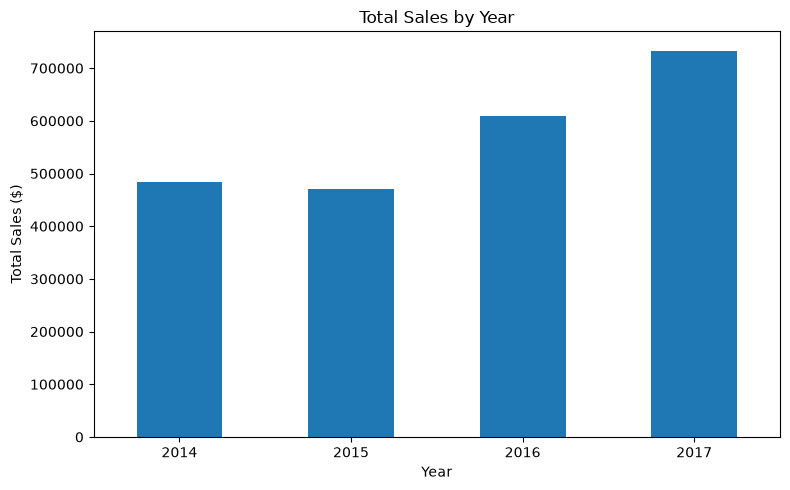

In [30]:
plt.figure(figsize=(8, 5))

yearly_analysis["Total_Sales"].plot(
    kind="bar",
    title="Total Sales by Year"
)

plt.xlabel("Year")
plt.ylabel("Total Sales ($)")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    "total_sales_by_year.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

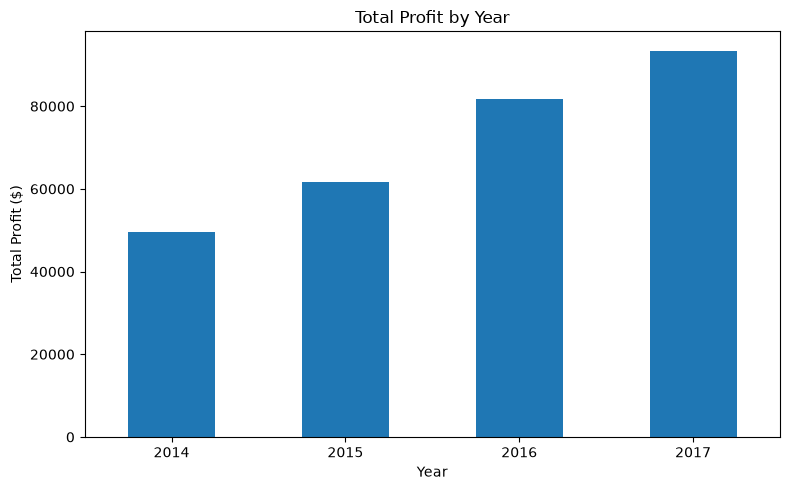

In [31]:
plt.figure(figsize=(8, 5))

yearly_analysis["Total_Profit"].plot(
    kind="bar",
    title="Total Profit by Year"
)

plt.xlabel("Year")
plt.ylabel("Total Profit ($)")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    "total_profit_by_year.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

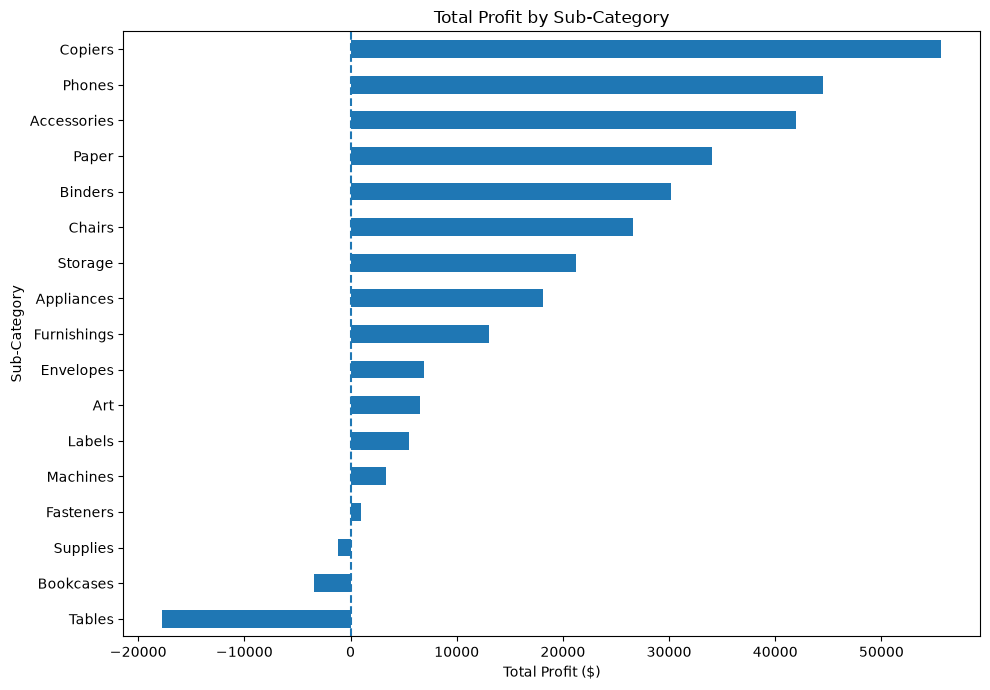

In [32]:
plt.figure(figsize=(10, 7))

subcategory_analysis["Total_Profit"].sort_values().plot(
    kind="barh",
    title="Total Profit by Sub-Category"
)

plt.axvline(x=0, linestyle="--")
plt.xlabel("Total Profit ($)")
plt.ylabel("Sub-Category")
plt.tight_layout()

plt.savefig(
    "profit_by_subcategory.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

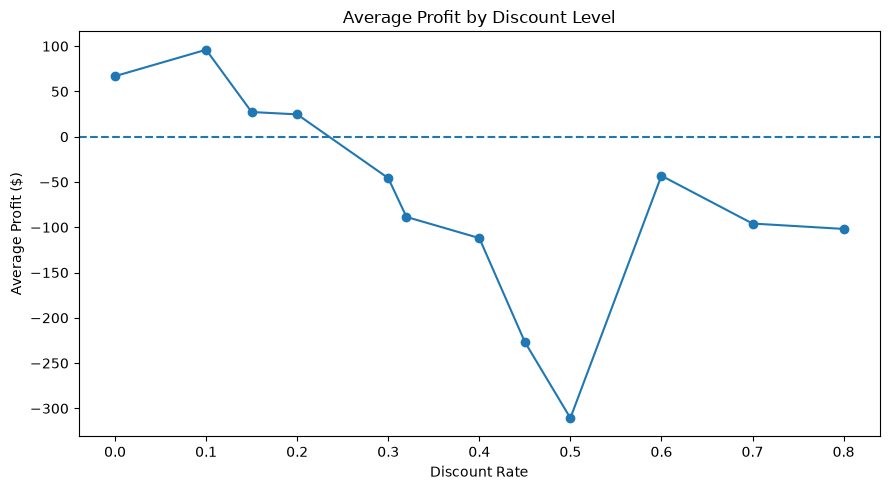

In [33]:
plt.figure(figsize=(9, 5))

discount_analysis["Average_Profit"].plot(
    kind="line",
    marker="o",
    title="Average Profit by Discount Level"
)

plt.axhline(y=0, linestyle="--")
plt.xlabel("Discount Rate")
plt.ylabel("Average Profit ($)")
plt.tight_layout()

plt.savefig(
    "average_profit_by_discount.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [34]:
import os

print("Current Project Folder:")
print(os.getcwd())

print("\nProject Files:")
for file in sorted(os.listdir()):
    print(file)

Current Project Folder:
c:\Users\basma\Downloads\archive

Project Files:
Sales_Data_Analysis.ipynb
Sample - Superstore.csv
archive
average_profit_by_discount.png
bottom_10_products.csv
category_analysis.csv
discount_analysis.csv
monthly_sales.csv
profit_by_subcategory.png
region_analysis.csv
sales_analysis.py
segment_analysis.csv
shipping_analysis.csv
subcategory_analysis.csv
top_10_products.csv
total_profit_by_year.png
total_sales_by_year.png
yearly_analysis.csv


In [35]:
discount_analysis = df.groupby("Discount").agg(
    Number_of_Rows=("Order ID", "count"),
    Average_Sales=("Sales", "mean"),
    Average_Profit=("Profit", "mean"),
    Total_Profit=("Profit", "sum")
).round(2)

discount_analysis.to_csv("discount_analysis.csv")

discount_analysis

,Number_of_Rows,Average_Sales,Average_Profit,Total_Profit
Discount,,,,
0.00,4798,226.74,66.90,320987.60
0.10,94,578.40,96.06,9029.18
0.15,52,529.97,27.29,1418.99
0.20,3657,209.08,24.70,90337.31
0.30,227,454.74,-45.68,-10369.28
0.32,27,536.79,-88.56,-2391.14
0.40,206,565.13,-111.93,-23057.05
0.45,11,498.63,-226.65,-2493.11
0.50,66,892.71,-310.70,-20506.43


In [36]:
# Analyze profitability by sub-category

subcategory_analysis = df.groupby("Sub-Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum")
).round(2)

subcategory_analysis = subcategory_analysis.sort_values(
    by="Total_Profit",
    ascending=True
)

subcategory_analysis

,Total_Sales,Total_Profit,Total_Quantity
Sub-Category,,,
Tables,206965.53,-17725.48,1241
Bookcases,114880.00,-3472.56,868
Supplies,46673.54,-1189.10,647
Fasteners,3024.28,949.52,914
Machines,189238.63,3384.76,440
Labels,12486.31,5546.25,1400
Art,27118.79,6527.79,3000
Envelopes,16476.40,6964.18,906
Furnishings,91705.16,13059.14,3563


In [37]:
subcategory_analysis["Profit_Margin_%"] = (
    subcategory_analysis["Total_Profit"]
    / subcategory_analysis["Total_Sales"]
    * 100
).round(2)

subcategory_analysis.sort_values(
    by="Profit_Margin_%",
    ascending=True
)

,Total_Sales,Total_Profit,Total_Quantity,Profit_Margin_%
Sub-Category,,,,
Tables,206965.53,-17725.48,1241,-8.56
Bookcases,114880.00,-3472.56,868,-3.02
Supplies,46673.54,-1189.10,647,-2.55
Machines,189238.63,3384.76,440,1.79
Chairs,328449.10,26590.17,2356,8.10
Storage,223843.61,21278.83,3158,9.51
Phones,330007.05,44515.73,3289,13.49
Furnishings,91705.16,13059.14,3563,14.24
Binders,203412.73,30221.76,5974,14.86


In [38]:
subcategory_analysis.to_csv(
    "subcategory_analysis.csv",
    index=True
)

print("Sub-category analysis saved successfully!")

Sub-category analysis saved successfully!


In [39]:
import os

for file in os.listdir("."):
    if file.endswith(".png"):
        print(file)

average_profit_by_discount.png
profit_by_subcategory.png
total_profit_by_year.png
total_sales_by_year.png


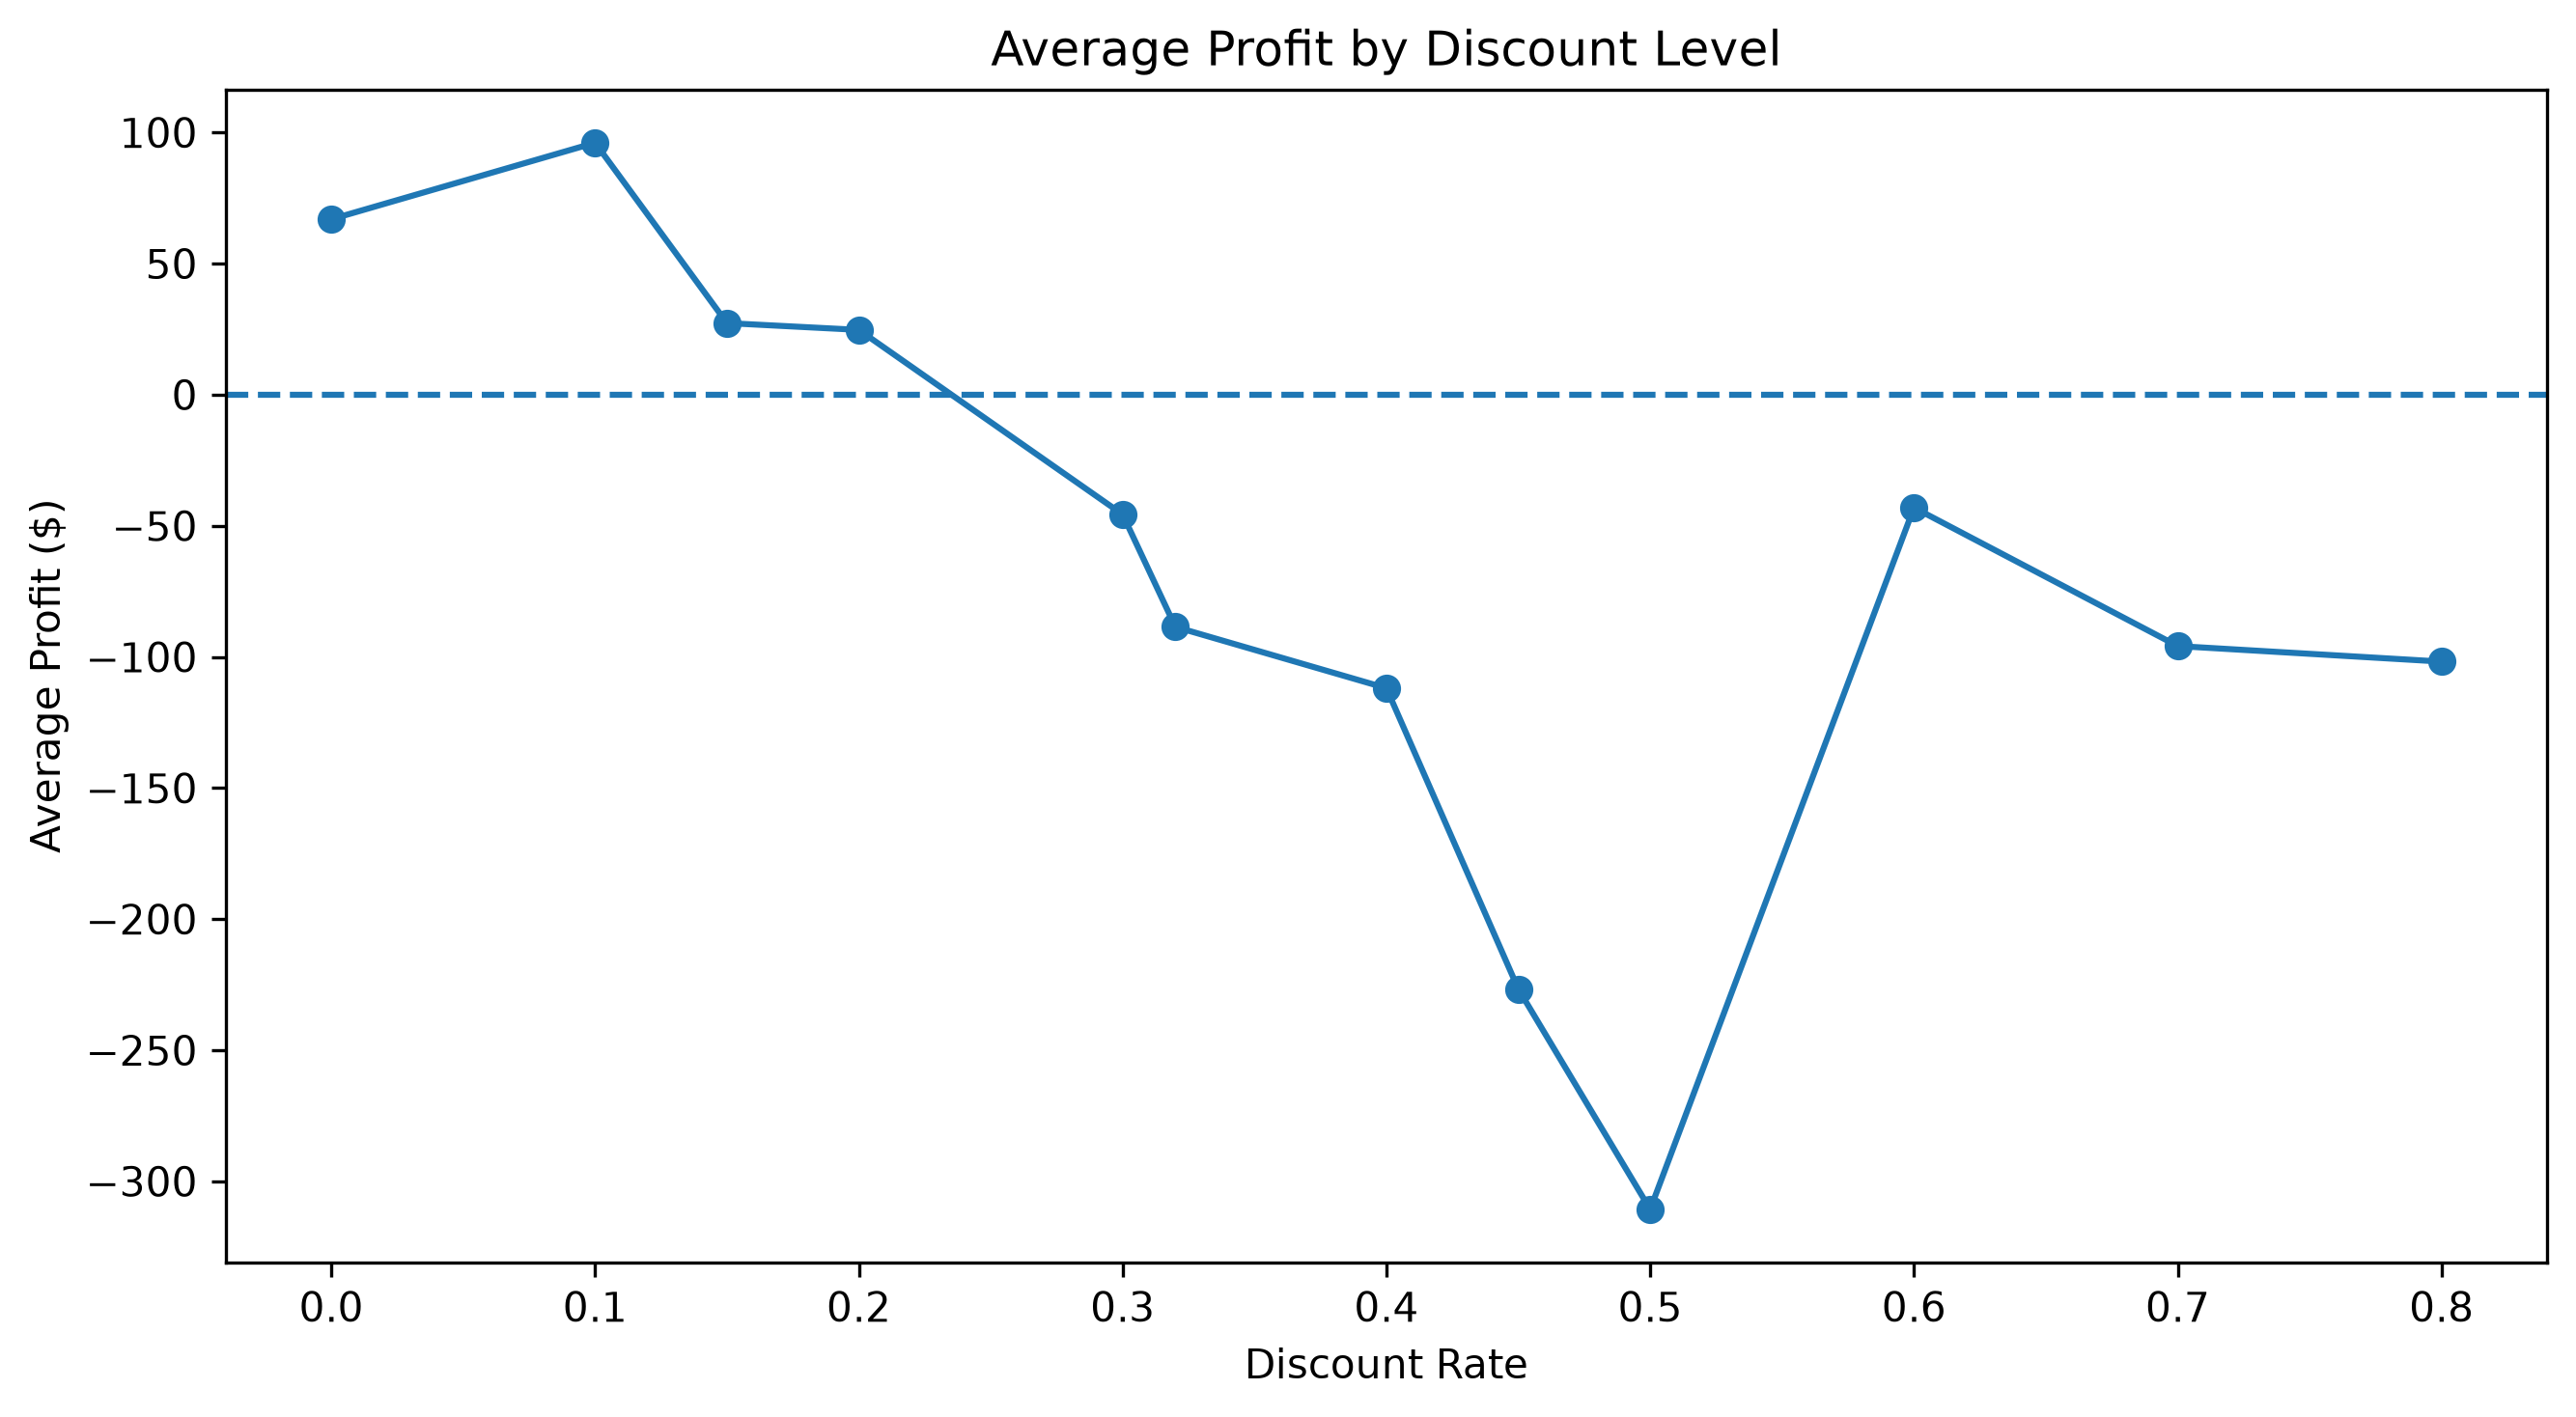

In [40]:
from IPython.display import Image, display

display(Image(filename="average_profit_by_discount.png"))

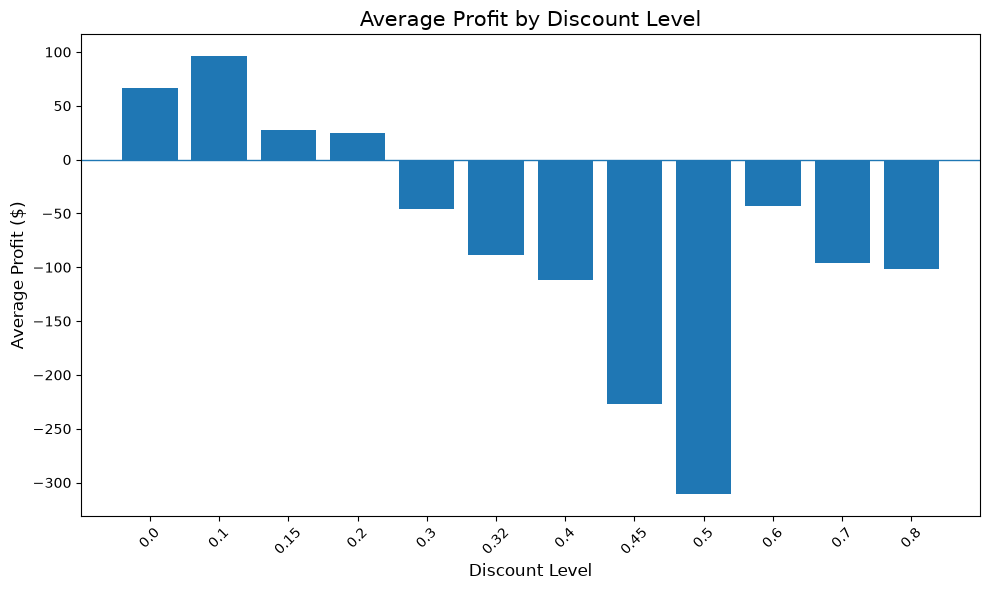

In [41]:
import matplotlib.pyplot as plt

discount_plot = discount_analysis.sort_index()

plt.figure(figsize=(10, 6))

plt.bar(
    discount_plot.index.astype(str),
    discount_plot["Average_Profit"]
)

plt.axhline(y=0, linewidth=1)

plt.title("Average Profit by Discount Level", fontsize=15)
plt.xlabel("Discount Level", fontsize=12)
plt.ylabel("Average Profit ($)", fontsize=12)

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "average_profit_by_discount_improved.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

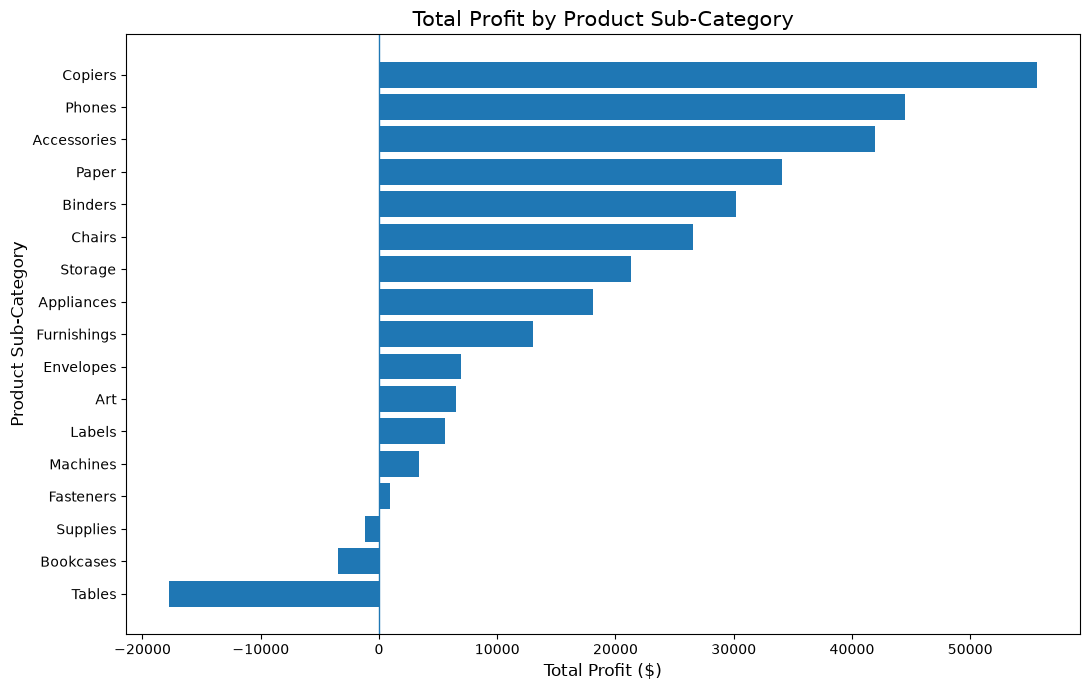

In [42]:
import matplotlib.pyplot as plt

subcategory_plot = subcategory_analysis.sort_values(
    by="Total_Profit",
    ascending=True
)

plt.figure(figsize=(11, 7))

plt.barh(
    subcategory_plot.index,
    subcategory_plot["Total_Profit"]
)

plt.axvline(x=0, linewidth=1)

plt.title("Total Profit by Product Sub-Category", fontsize=15)
plt.xlabel("Total Profit ($)", fontsize=12)
plt.ylabel("Product Sub-Category", fontsize=12)

plt.tight_layout()

plt.savefig(
    "profit_by_subcategory_improved.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

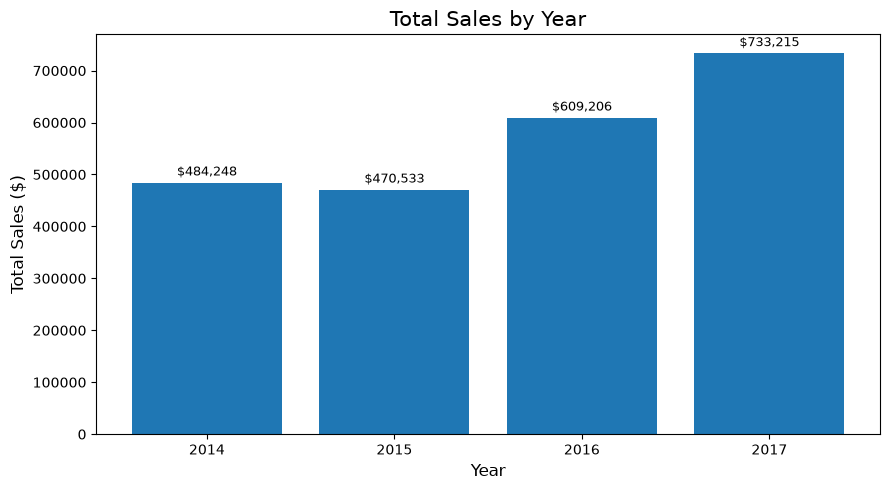

In [43]:
import matplotlib.pyplot as plt

sales_by_year = yearly_analysis.sort_index()

plt.figure(figsize=(9, 5))

bars = plt.bar(
    sales_by_year.index.astype(str),
    sales_by_year["Total_Sales"]
)

plt.bar_label(
    bars,
    labels=[
        f"${value:,.0f}"
        for value in sales_by_year["Total_Sales"]
    ],
    padding=3,
    fontsize=9
)

plt.title("Total Sales by Year", fontsize=15)
plt.xlabel("Year", fontsize=12)
plt.ylabel("Total Sales ($)", fontsize=12)

plt.tight_layout()

plt.savefig(
    "total_sales_by_year_improved.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

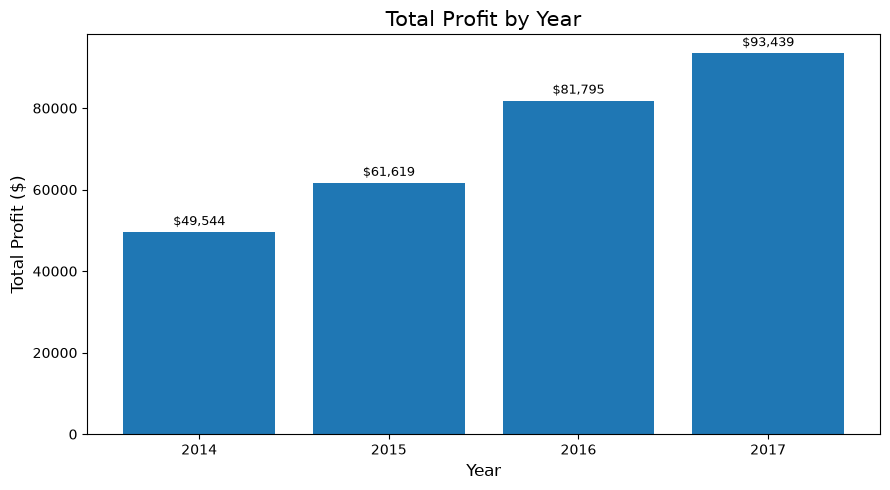

In [44]:
import matplotlib.pyplot as plt

profit_by_year = yearly_analysis.sort_index()

plt.figure(figsize=(9, 5))

bars = plt.bar(
    profit_by_year.index.astype(str),
    profit_by_year["Total_Profit"]
)

plt.bar_label(
    bars,
    labels=[
        f"${value:,.0f}"
        for value in profit_by_year["Total_Profit"]
    ],
    padding=3,
    fontsize=9
)

plt.title("Total Profit by Year", fontsize=15)
plt.xlabel("Year", fontsize=12)
plt.ylabel("Total Profit ($)", fontsize=12)

plt.tight_layout()

plt.savefig(
    "total_profit_by_year_improved.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [45]:
import os

for file in sorted(os.listdir(".")):
    if file.endswith((".ipynb", ".csv", ".png", ".md", ".py")):
        print(file)

Sales_Data_Analysis.ipynb
Sample - Superstore.csv
average_profit_by_discount.png
average_profit_by_discount_improved.png
bottom_10_products.csv
category_analysis.csv
discount_analysis.csv
monthly_sales.csv
profit_by_subcategory.png
profit_by_subcategory_improved.png
region_analysis.csv
sales_analysis.py
segment_analysis.csv
shipping_analysis.csv
subcategory_analysis.csv
top_10_products.csv
total_profit_by_year.png
total_profit_by_year_improved.png
total_sales_by_year.png
total_sales_by_year_improved.png
yearly_analysis.csv


In [46]:
import os

print("README exists:", os.path.exists("README.md"))

README exists: False


In [47]:
readme_content = """
# Superstore Sales Data Analysis

## Project Overview
This project analyzes retail sales data to identify sales trends,
profitability patterns, and business improvement opportunities.

## Dataset
- Records: 9,994
- Original columns: 21
- Period: 2014–2017
- Missing values and duplicate rows: None found during initial checks

## Tools & Technologies
- Python
- Pandas
- Matplotlib
- Jupyter Notebook

## Key Performance Indicators
- Total Sales: $2,297,200.86
- Total Profit: $286,397.02
- Overall Profit Margin: 12.47%
- Total Orders: 5,009
- Unique Customers: 793
- Average Order Value: $458.61

## Key Findings
- Technology generated the highest sales and total profit among the
  three main product categories.
- The Central region had the lowest regional profit margin at 7.92%.
- Tables recorded the largest sub-category loss at $17,725.48.
- Copiers generated the highest total profit among sub-categories.
- Home Office had the highest profit margin among customer segments.
- Higher discount levels were associated with negative average profit
  in several discount groups.

## Business Recommendations
- Review pricing, discounts, and costs for loss-making sub-categories.
- Investigate regional differences in profitability.
- Evaluate promotions using both sales and profit metrics.
- Monitor monthly and yearly performance to support business planning.

## Project Workflow
1. Data loading and inspection
2. Data quality checks
3. Date feature engineering
4. Exploratory data analysis (EDA)
5. Sales and profit analysis
6. Product, regional, segment, and discount analysis
7. Data visualization
8. Exporting analytical results to CSV

## Project Goal
Turn retail sales data into actionable insights that support
better business decisions.
"""

with open("README.md", "w", encoding="utf-8") as file:
    file.write(readme_content.strip())

print("README.md created successfully!")

README.md created successfully!


In [48]:
import os

print("README exists:", os.path.exists("README.md"))

README exists: True


In [49]:
import json

with open("Sales_Data_Analysis.ipynb", "r", encoding="utf-8") as file:
    notebook = json.load(file)

cells = notebook["cells"]

print("Total cells:", len(cells))
print("Code cells:", sum(cell["cell_type"] == "code" for cell in cells))
print("Markdown cells:", sum(cell["cell_type"] == "markdown" for cell in cells))

errors = []

for i, cell in enumerate(cells):
    if cell["cell_type"] == "code":
        for output in cell.get("outputs", []):
            if output.get("output_type") == "error":
                errors.append((i + 1, output.get("ename"), output.get("evalue")))

print("\nSaved errors:", len(errors))

for error in errors:
    print(error)

Total cells: 30
Code cells: 29
Markdown cells: 1

Saved errors: 0


In [50]:
for i, cell in enumerate(cells, start=1):
    cell_type = cell["cell_type"]
    content = "".join(cell.get("source", []))
    first_line = content.strip().split("\n")[0] if content.strip() else "(empty cell)"

    print(f"{i}. [{cell_type}] {first_line[:100]}")

1. [code] import pandas as pd
2. [code] print("Dataset Shape:", df.shape)
3. [code] df.info()
4. [code] df.isnull().sum()
5. [code] print("Number of Duplicate Rows:", df.duplicated().sum())
6. [code] df["Order Date"] = pd.to_datetime(df["Order Date"])
7. [code] df[["Sales", "Quantity", "Discount", "Profit"]].describe()
8. [code] total_sales = df["Sales"].sum()
9. [code] category_analysis = df.groupby("Category").agg(
10. [code] category_analysis["Profit_Margin_%"] = (
11. [code] region_analysis = df.groupby("Region").agg(
12. [code] df["Order Year"] = df["Order Date"].dt.year
13. [code] import matplotlib.pyplot as plt
14. [code] yearly_analysis["Total_Profit"].plot(
15. [code] product_profit = df.groupby("Product Name").agg(
16. [code] bottom_10_products = product_profit.sort_values(
17. [code] discount_analysis = df.groupby("Discount").agg(
18. [code] discount_analysis["Average_Profit"].plot(
19. [code] subcategory_analysis = df.groupby("Sub-Category").agg(
20. [code] subcategory_anal

In [51]:
for cell_number in [1, 26, 27, 28, 29]:
    cell = cells[cell_number - 1]
    source = "".join(cell.get("source", []))

    print(f"\n{'=' * 15} CELL {cell_number} {'=' * 15}")
    print(source)


=============== CELL 1 ===============
import pandas as pd

df = pd.read_csv("Sample - Superstore.csv", encoding="latin1")

df.head()

=============== CELL 26 ===============
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_orders = df["Order ID"].nunique()
total_customers = df["Customer ID"].nunique()
total_quantity = df["Quantity"].sum()

profit_margin = (total_profit / total_sales) * 100
average_order_value = total_sales / total_orders

print(f"Total Sales: ${total_sales:,.2f}")
print(f"Total Profit: ${total_profit:,.2f}")
print(f"Profit Margin: {profit_margin:.2f}%")
print(f"Total Orders: {total_orders:,}")
print(f"Total Customers: {total_customers:,}")
print(f"Total Quantity Sold: {total_quantity:,}")
print(f"Average Order Value: ${average_order_value:,.2f}")

=============== CELL 27 ===============
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
prin

Superstore Sales Data Analysis

Project Overview

This project analyzes retail sales data to understand sales performance, profitability, customer segments, and product trends.

Business Objectives

- Measure key business performance indicators (KPIs).
- Identify the most and least profitable products.
- Compare sales and profitability across regions and categories.
- Analyze the relationship between discounts and profit.
- Explore yearly and monthly sales trends.

Tools and Technologies

- Python
- Pandas
- Matplotlib